# 🏈 NFL Data Analysis — Part 2: Offensive Strategies

Now that you know how a game is structured, let's look at **how teams try to move the ball through the air**. This dataset focuses on **passing plays (QB dropbacks)** — the heart of the modern NFL — so we'll explain throwing strategies, formations, and how defenses try to stop them.

> ⚠️ **Note on this dataset:** Every play here is a QB dropback (a passing play). This is the NFL's pass-rush tracking dataset, so we focus on the passing game rather than comparing pass vs run.

---
## What you'll learn
- What happens on a passing play (completions, sacks, interceptions)
- What formations tell us about a team's intent
- How coverage schemes affect the offense
- How play action and defensive pressure change outcomes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='deep')

games  = pd.read_csv('../data/games.csv')
plays  = pd.read_csv('../data/plays.csv')
pff    = pd.read_csv('../data/pffScoutingData.csv')

# Merge games info for week context
plays = plays.merge(games[['gameId', 'week', 'homeTeamAbbr', 'visitorTeamAbbr']], on='gameId', how='left')

# Every play is a QB dropback (passing play)
pass_plays = plays[plays['passResult'].notna()].copy()
print(f'Total dropback plays: {len(plays):,}')
print(f'With a pass result:   {len(pass_plays):,} ({len(pass_plays)/len(plays)*100:.1f}%)')
print()
print('Dropback types (how the QB set up to throw):')
print(plays['dropBackType'].value_counts())

/home/armand/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Total dropback plays: 8,557
With a pass result:   8,557 (100.0%)

Dropback types (how the QB set up to throw):
dropBackType
TRADITIONAL               6542
SCRAMBLE                   899
DESIGNED_ROLLOUT_RIGHT     285
DESIGNED_ROLLOUT_LEFT      149
SCRAMBLE_ROLLOUT_RIGHT     125
SCRAMBLE_ROLLOUT_LEFT       23
DESIGNED_RUN                 5
UNKNOWN                      1
Name: count, dtype: int64


---
## 1 — What happens on a passing play?

> **NFL Basics:** When the QB drops back to pass, several things can happen:
> - **Complete pass** ✅ — the receiver catches it (offense gains yards)
> - **Incomplete pass** ❌ — nobody catches it (no gain, clock stops)
> - **Sack** 🛑 — the defense tackles the QB before he throws (big loss)
> - **Interception** 💀 — the defense catches it (a turnover, disaster for the offense)
> - **Scramble** 🏃 — the QB runs the ball himself

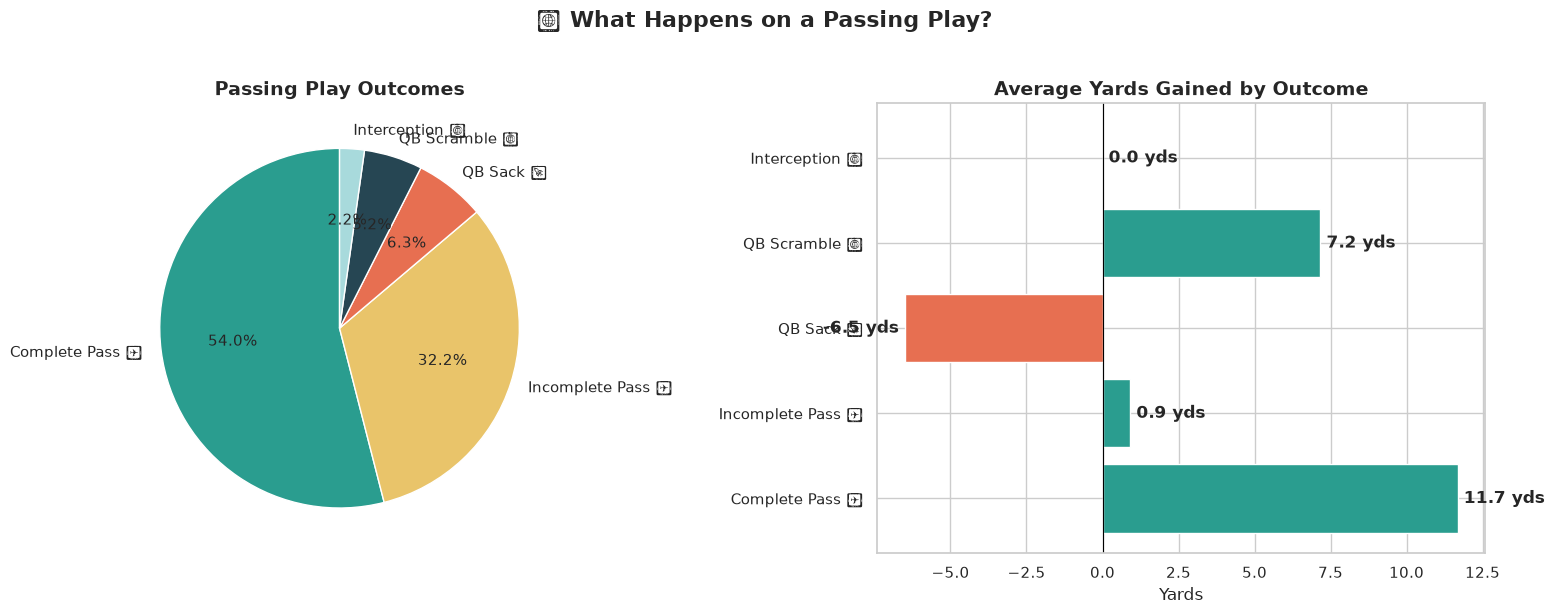

In [2]:
# passResult codes
result_map = {
    'C': 'Complete Pass ✅',
    'I': 'Incomplete Pass ❌',
    'S': 'QB Sack 🛑',
    'IN': 'Interception 💀',
    'R': 'QB Scramble 🏃'
}
pass_plays['result_label'] = pass_plays['passResult'].map(result_map).fillna('Other')
result_counts = pass_plays['result_label'].value_counts()

# Yards per result
yards_by_result = pass_plays.groupby('result_label')['playResult'].mean().reindex(result_counts.index)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pie chart of outcomes
colors_out = ['#2a9d8f', '#e9c46a', '#e76f51', '#264653', '#a8dadc']
axes[0].pie(result_counts.values, labels=result_counts.index,
            autopct='%1.1f%%', colors=colors_out, startangle=90,
            textprops={'fontsize': 11})
axes[0].set_title('Passing Play Outcomes', fontsize=14, fontweight='bold')

# Average yards per outcome
bar_colors = ['#2a9d8f' if y > 0 else '#e76f51' for y in yards_by_result.values]
axes[1].barh(yards_by_result.index, yards_by_result.values, color=bar_colors, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8)
for i, val in enumerate(yards_by_result.values):
    axes[1].text(val + 0.2 if val >= 0 else val - 0.2, i,
                 f'{val:.1f} yds', va='center',
                 ha='left' if val >= 0 else 'right', fontweight='bold')
axes[1].set_title('Average Yards Gained by Outcome', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Yards')

plt.suptitle('📡 What Happens on a Passing Play?', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 2 — Offensive Formations: What do they reveal?

> **NFL Basics:** A **formation** is how players line up before the snap. Different formations signal different strategies:
> - **Shotgun**: QB stands back — usually a passing play
> - **Singleback**: 1 running back — balanced, can run or pass
> - **Empty**: No running backs — pure passing intent
> - **I-Form/Pistol**: Classic run formations

---
## 3 — Down & Distance: When is it easiest to complete a pass?

> **Key insight:** The situation changes how hard it is to throw. On 3rd & long, the defense knows a pass is coming and defends it aggressively, so completion rates drop. On early downs with short distance, passing is easier and safer.

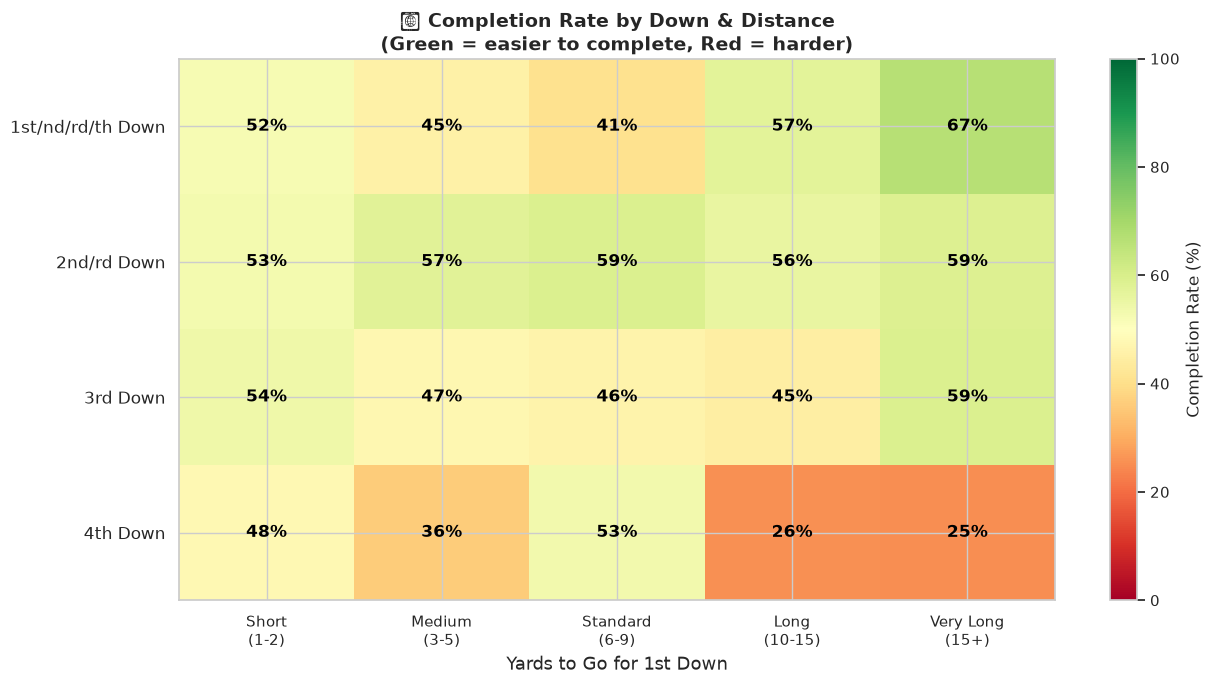


Key insight: longer distances are harder to complete — the defense expects the pass and defends deeper


In [4]:
strategy = plays.dropna(subset=['down']).copy()
strategy = strategy[strategy['down'].between(1, 4)]
strategy['is_complete'] = (strategy['passResult'] == 'C').astype(int)
strategy['down'] = strategy['down'].astype(int)

# Bin yards to go
bins = [0, 2, 5, 9, 15, 100]
labels = ['Short\n(1-2)', 'Medium\n(3-5)', 'Standard\n(6-9)', 'Long\n(10-15)', 'Very Long\n(15+)']
strategy['ytg_group'] = pd.cut(strategy['yardsToGo'], bins=bins, labels=labels)

pivot = strategy.groupby(['down', 'ytg_group'], observed=True)['is_complete'].mean().unstack() * 100

fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(pivot.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=11)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels([f'{d}st/nd/rd/th Down' if d == 1 else f'{d}nd/rd Down' if d == 2
                    else f'{d}rd Down' if d == 3 else f'{d}th Down'
                    for d in pivot.index], fontsize=12)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val:.0f}%', ha='center', va='center',
                    fontsize=12, fontweight='bold',
                    color='white' if val > 75 or val < 25 else 'black')

plt.colorbar(im, ax=ax, label='Completion Rate (%)')
ax.set_xlabel('Yards to Go for 1st Down', fontsize=13)
ax.set_title('🎯 Completion Rate by Down & Distance\n(Green = easier to complete, Red = harder)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print('\nKey insight: longer distances are harder to complete — the defense expects the pass and defends deeper')

---
## 4 — Defenders in the Box: Reading the Defense

> **NFL Basics:** The **box** is the area near the line of scrimmage. If a defense puts many defenders there (6+), they're expecting a run. Smart offenses audible to a pass when they see a stacked box.

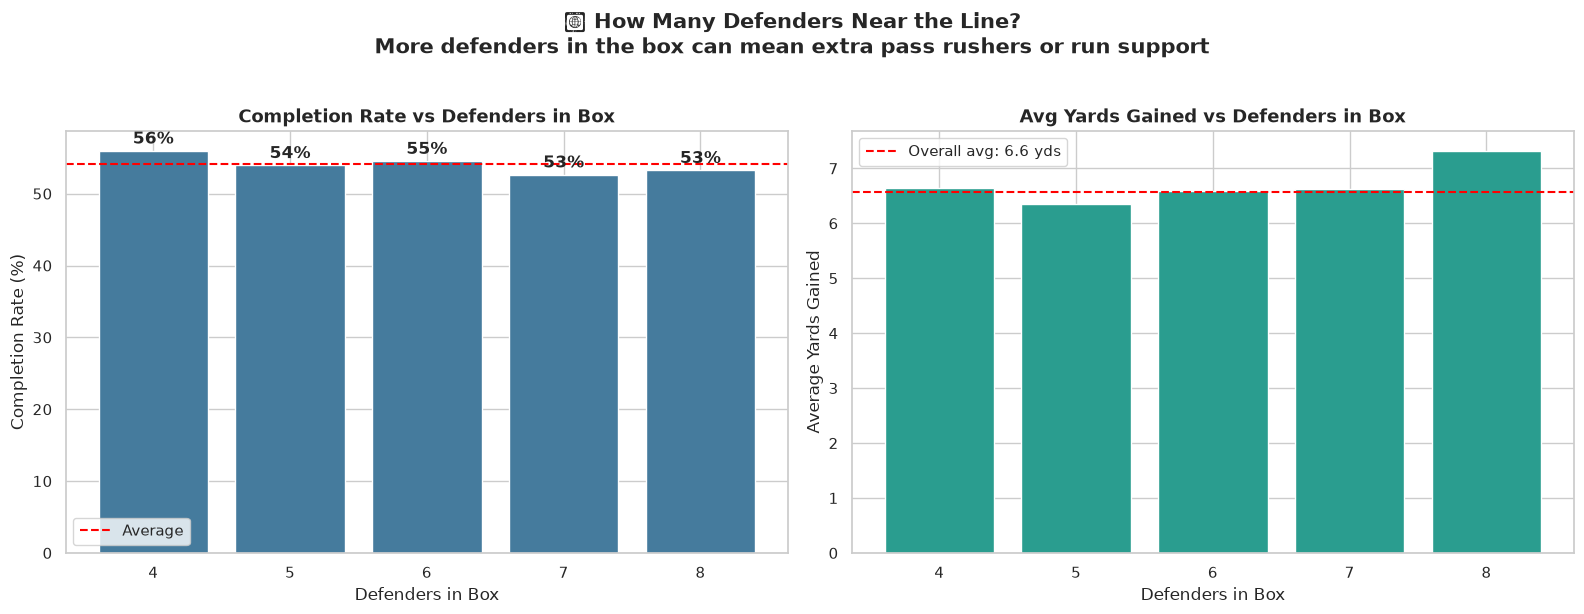

In [5]:
box_data = plays.dropna(subset=['defendersInBox']).copy()
box_data['is_complete'] = (box_data['passResult'] == 'C').astype(int)
box_data['defendersInBox'] = box_data['defendersInBox'].astype(int)

grouped = box_data.groupby('defendersInBox').agg(
    num_plays=('is_complete', 'count'),
    completion_rate=('is_complete', 'mean'),
    avg_yards=('playResult', 'mean')
).reset_index()
grouped = grouped[grouped['num_plays'] > 50]  # Only meaningful sample sizes

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Completion rate vs defenders in box
axes[0].bar(grouped['defendersInBox'], grouped['completion_rate'] * 100,
            color='#457b9d', edgecolor='white')
axes[0].axhline(grouped['completion_rate'].mean() * 100, color='red', linestyle='--',
                linewidth=1.5, label='Average')
axes[0].set_xlabel('Defenders in Box', fontsize=12)
axes[0].set_ylabel('Completion Rate (%)', fontsize=12)
axes[0].set_title('Completion Rate vs Defenders in Box', fontsize=13, fontweight='bold')
axes[0].legend()
for x, y in zip(grouped['defendersInBox'], grouped['completion_rate'] * 100):
    axes[0].text(x, y + 1, f'{y:.0f}%', ha='center', fontweight='bold')

# Average yards gained
bar_colors3 = ['#2a9d8f' if y > 0 else '#e76f51' for y in grouped['avg_yards']]
axes[1].bar(grouped['defendersInBox'], grouped['avg_yards'],
            color=bar_colors3, edgecolor='white')
axes[1].axhline(plays['playResult'].mean(), color='red', linestyle='--', linewidth=1.5,
                label=f'Overall avg: {plays["playResult"].mean():.1f} yds')
axes[1].set_xlabel('Defenders in Box', fontsize=12)
axes[1].set_ylabel('Average Yards Gained', fontsize=12)
axes[1].set_title('Avg Yards Gained vs Defenders in Box', fontsize=13, fontweight='bold')
axes[1].legend()

plt.suptitle('📦 How Many Defenders Near the Line?\nMore defenders in the box can mean extra pass rushers or run support', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 5 — Play Action: Faking the Run to Open the Pass

> **NFL Basics:** A **play action** fake is when the QB pretends to hand the ball to a running back, then passes instead. It tricks the defense into thinking it's a run, giving receivers more time to get open.

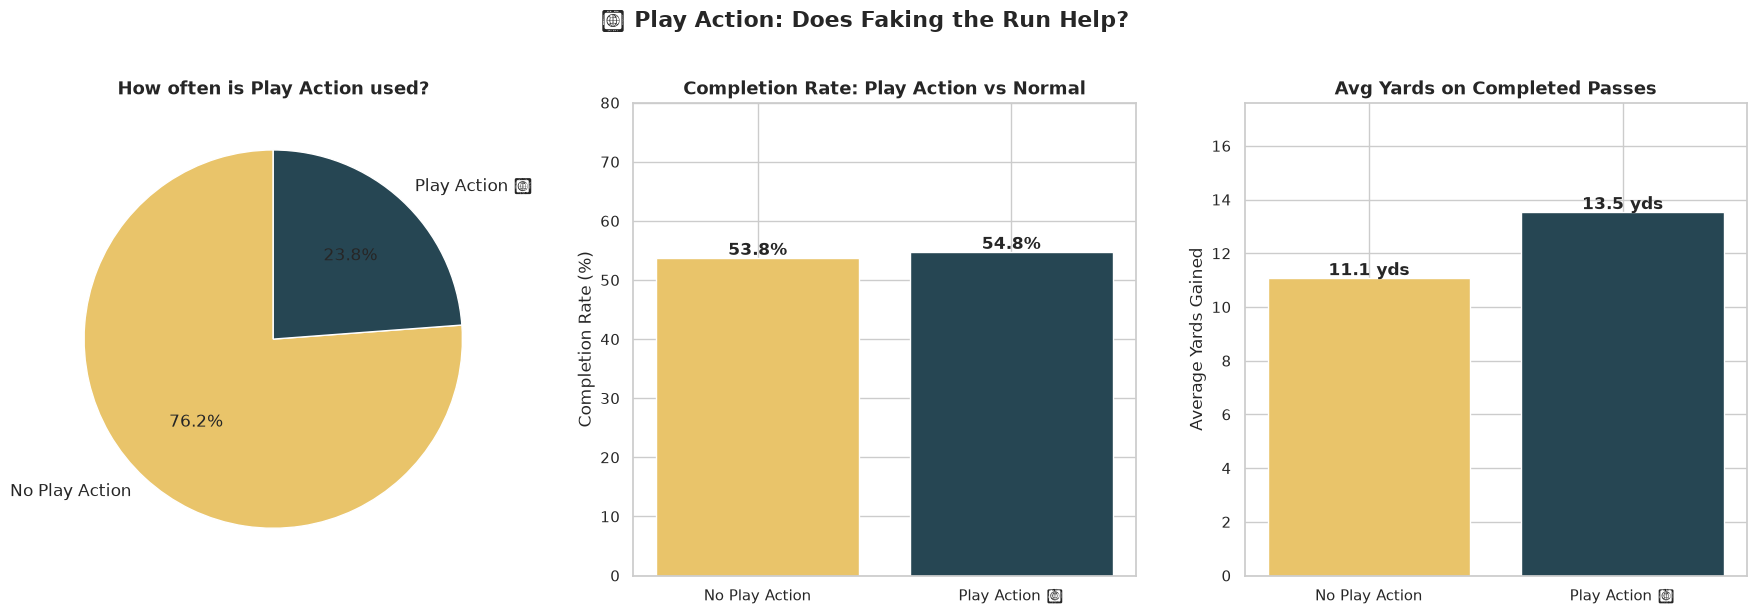

In [6]:
pa_data = pass_plays.dropna(subset=['pff_playAction']).copy()
pa_data['play_action_label'] = pa_data['pff_playAction'].map({1: 'Play Action 🎭', 0: 'No Play Action'})

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Usage
pa_counts = pa_data['play_action_label'].value_counts()
axes[0].pie(pa_counts.values, labels=pa_counts.index, autopct='%1.1f%%',
            colors=['#e9c46a', '#264653'], startangle=90, textprops={'fontsize': 12})
axes[0].set_title('How often is Play Action used?', fontsize=13, fontweight='bold')

# Complete pass rate
complete_rate = pa_data.groupby('play_action_label').apply(
    lambda x: (x['passResult'] == 'C').mean() * 100
).reset_index()
complete_rate.columns = ['label', 'completion_rate']
axes[1].bar(complete_rate['label'], complete_rate['completion_rate'],
            color=['#e9c46a', '#264653'], edgecolor='white')
for x, y in enumerate(complete_rate['completion_rate']):
    axes[1].text(x, y + 0.5, f'{y:.1f}%', ha='center', fontweight='bold', fontsize=12)
axes[1].set_ylabel('Completion Rate (%)')
axes[1].set_title('Completion Rate: Play Action vs Normal', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 80)

# Avg yards on completed passes
completed = pa_data[pa_data['passResult'] == 'C']
avg_yds = completed.groupby('play_action_label')['playResult'].mean()
axes[2].bar(avg_yds.index, avg_yds.values, color=['#e9c46a', '#264653'], edgecolor='white')
for x, y in enumerate(avg_yds.values):
    axes[2].text(x, y + 0.1, f'{y:.1f} yds', ha='center', fontweight='bold', fontsize=12)
axes[2].set_ylabel('Average Yards Gained')
axes[2].set_title('Avg Yards on Completed Passes', fontsize=13, fontweight='bold')
axes[2].set_ylim(0, avg_yds.max() * 1.3)

plt.suptitle('🎭 Play Action: Does Faking the Run Help?', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 6 — Pass Coverage Schemes: How the Defense Reacts

> **NFL Basics:** When the offense passes, the defense uses a **coverage scheme**:
> - **Man coverage**: Each defender follows one specific receiver everywhere
> - **Zone coverage**: Defenders guard areas of the field, not individual players
> - **Cover-0/Cover-1**: Man-heavy, aggressive, risky
> - **Cover-2/Cover-3**: Zone-based, safer but can be beaten by precise passing

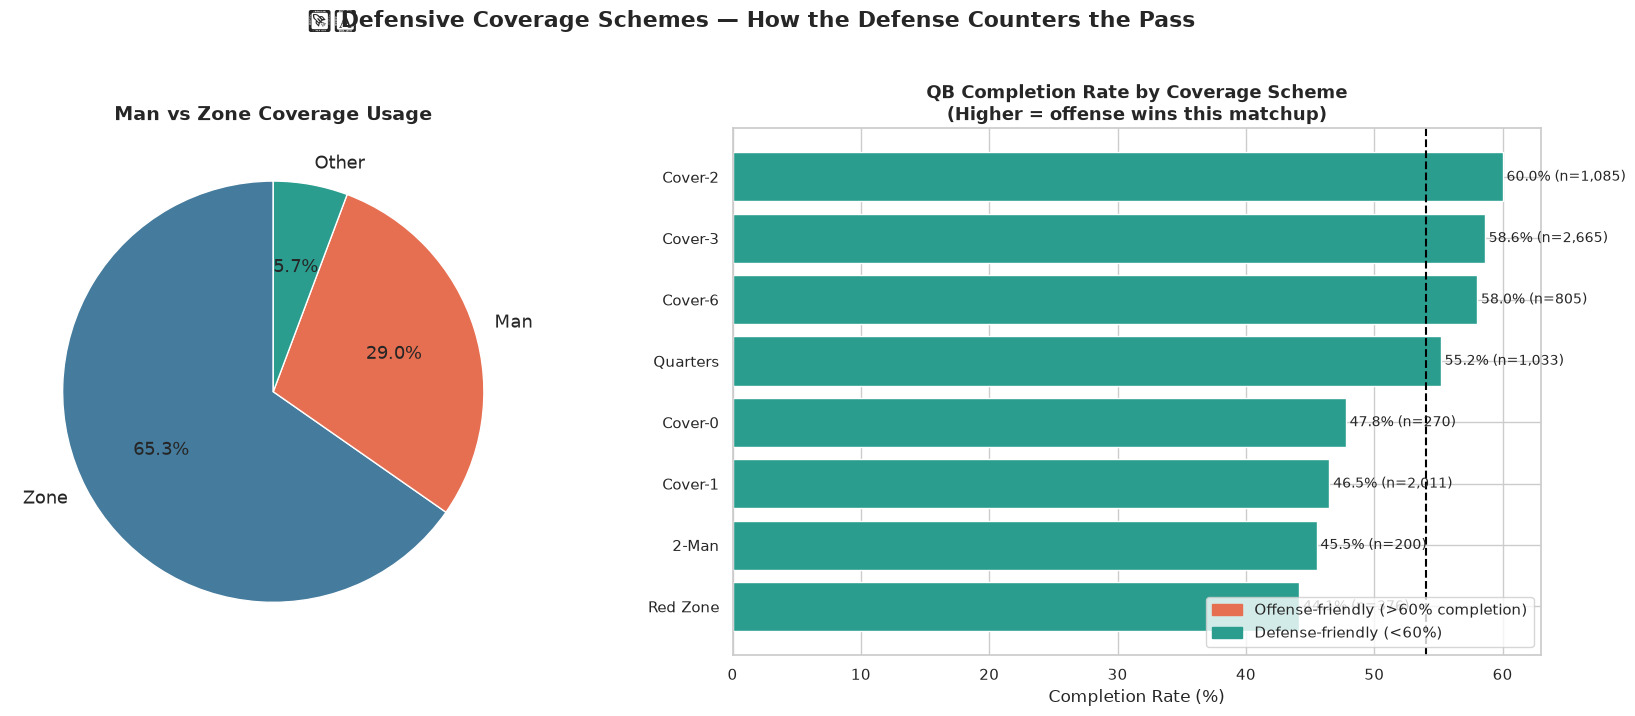

In [7]:
cov_data = pass_plays.dropna(subset=['pff_passCoverage', 'pff_passCoverageType']).copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Coverage type usage
type_counts = cov_data['pff_passCoverageType'].value_counts()
axes[0].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
            colors=['#457b9d', '#e76f51', '#2a9d8f'], startangle=90,
            textprops={'fontsize': 13})
axes[0].set_title('Man vs Zone Coverage Usage', fontsize=14, fontweight='bold')

# Completion rate per coverage scheme
scheme_stats = cov_data.groupby('pff_passCoverage').agg(
    n=('passResult', 'count'),
    completion_rate=('passResult', lambda x: (x == 'C').mean() * 100),
    avg_yards=('playResult', 'mean')
).reset_index()
scheme_stats = scheme_stats[scheme_stats['n'] > 100].sort_values('completion_rate', ascending=True)

bar_colors_cov = ['#e76f51' if r > 60 else '#2a9d8f' for r in scheme_stats['completion_rate']]
axes[1].barh(scheme_stats['pff_passCoverage'], scheme_stats['completion_rate'],
             color=bar_colors_cov, edgecolor='white')
axes[1].axvline(cov_data.apply(lambda r: r['passResult'] == 'C', axis=1).mean() * 100,
                color='black', linestyle='--', linewidth=1.5,
                label=f'Overall: {(cov_data["passResult"]=="C").mean()*100:.1f}%')
for i, (val, n) in enumerate(zip(scheme_stats['completion_rate'], scheme_stats['n'])):
    axes[1].text(val + 0.3, i, f'{val:.1f}% (n={n:,})', va='center', fontsize=10)
axes[1].set_xlabel('Completion Rate (%)', fontsize=12)
axes[1].set_title('QB Completion Rate by Coverage Scheme\n(Higher = offense wins this matchup)', 
                  fontsize=13, fontweight='bold')
axes[1].legend()
red_patch = mpatches.Patch(color='#e76f51', label='Offense-friendly (>60% completion)')
green_patch = mpatches.Patch(color='#2a9d8f', label='Defense-friendly (<60%)')
axes[1].legend(handles=[red_patch, green_patch], loc='lower right')

plt.suptitle('🛡️ Defensive Coverage Schemes — How the Defense Counters the Pass', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Summary

| Concept | Key Takeaway |
|---|---|
| Passing outcomes | ~54% of dropbacks are completed; sacks and interceptions are the worst outcomes |
| Shotgun formation | The most common passing formation by far |
| 3rd & long | Completion rates drop — the defense knows a pass is coming |
| Defenders in box | More defenders near the line changes how the pass develops |
| Play action | Faking the run opens up bigger, higher-percentage passing plays |
| Cover-0 | Very aggressive man coverage — risky for the defense |

**➡️ Next up:** `03_team_comparison.ipynb` — which teams are best and why, explained with data.